# NN-Interp: learning multiplication

We train a **2 → 4 → 1** network (17 trainable parameters) on independent uniform inputs in $[-2, 2]^2$, with target $xy$. The single hidden layer uses `tanh`; the output is linear. Our goal is **held-out MSE < 0.001**.

We plot the learned multiplication surface, inspect four diagnostic cases, and train four nonlinear inverse probes. Each probe takes **one hidden neuron's activation** $z$ and predicts an **unordered pair** of original inputs.

Run from top to bottom with PyTorch and Matplotlib installed. Adam and L-BFGS both use the full **4,096-example training batch**. Validation has 4,096 independent examples; the final test set has 16,384. Training can take a few minutes on a CPU.

In [1]:
# Run this once if the packages are missing, then restart the kernel:
# %pip install torch matplotlib

In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt

# One thread avoids overhead for these tiny matrices.
torch.set_num_threads(1)
torch.manual_seed(42)
plt.rcParams["figure.figsize"] = (8, 4)


def sample_inputs(n, generator=None):
    return 4 * torch.rand(n, 2, generator=generator) - 2


def product(inputs):
    return inputs[:, :1] * inputs[:, 1:2]


train_x = sample_inputs(4096)
validation_x = sample_inputs(4096)
# An independent generator keeps the final test set separate from tuning.
test_x = sample_inputs(16384, generator=torch.Generator().manual_seed(2026))
train_y = product(train_x)
validation_y = product(validation_x)
test_y = product(test_x)

## Train the multiplication network

`activations()` returns the four values **after** the hidden layer's `tanh`. Adam learns the overall shape, then full-batch L-BFGS refines the same 17 parameters. Neither optimizer uses validation or test examples for gradients.

Snapshots report MSE on a fixed held-out **validation** set. The independent final **test** set is evaluated after training. Random test-set MSE measures average error, not a bound at every input.

Step 0: held-out validation MSE = 2.36125851
Adam step 10: held-out validation MSE = 1.95247006
Adam step 50: held-out validation MSE = 1.49048316
Adam step 100: held-out validation MSE = 0.706597328
Adam step 500: held-out validation MSE = 0.0161042642


Adam step 2000: held-out validation MSE = 0.00283681462


Adam step 6000: held-out validation MSE = 0.000531186932


Adam step 12000: held-out validation MSE = 0.000281068322


After L-BFGS: held-out validation MSE = 6.19541396e-08

Parameters: 17
Final held-out test MSE: 6.39729336e-08
Final held-out test MAE: 0.000189
MSE < 0.001: True


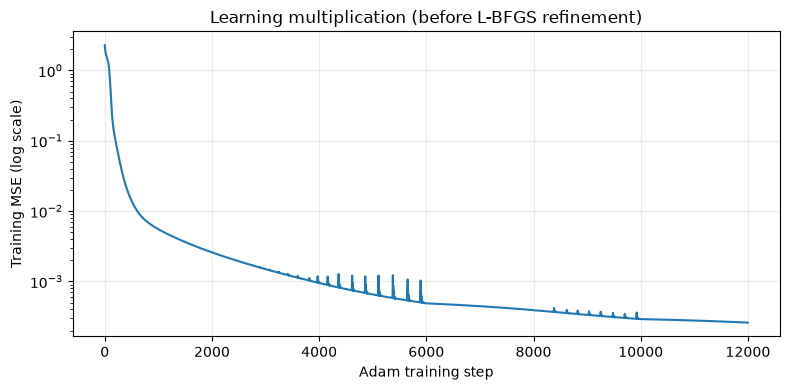

In [3]:
class MultiplicationNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden1 = nn.Linear(2, 4)
        self.output = nn.Linear(4, 1)

    def activations(self, inputs):
        return torch.tanh(self.hidden1(inputs))

    def forward(self, inputs):
        return self.output(self.activations(inputs))


model = MultiplicationNet()
loss_fn = nn.MSELoss()
losses = []
snapshots = []
snapshot_steps = {0, 10, 50, 100, 500, 2000, 6000, 12000}
stage_axis = torch.linspace(-2, 2, 41)
stage_xx, stage_yy = torch.meshgrid(stage_axis, stage_axis, indexing="xy")
stage_grid = torch.stack([stage_xx.flatten(), stage_yy.flatten()], dim=1)


@torch.no_grad()
def save_snapshot(label):
    mse = loss_fn(model(validation_x), validation_y).item()
    surface = model(stage_grid).reshape(stage_xx.shape).clone()
    snapshots.append((label, mse, surface))
    print(f"{label}: held-out validation MSE = {mse:.9g}")


optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=[6000, 10000], gamma=0.3
)
model.train()
save_snapshot("Step 0")
for step in range(1, 12001):
    loss = loss_fn(model(train_x), train_y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    scheduler.step()
    losses.append(loss.item())
    if step in snapshot_steps:
        save_snapshot(f"Adam step {step}")

# Refine the fit without adding neurons or changing the activation function.
optimizer = torch.optim.LBFGS(
    model.parameters(), max_iter=1500, line_search_fn="strong_wolfe",
    tolerance_grad=1e-9, tolerance_change=1e-12,
)


def refine_closure():
    optimizer.zero_grad()
    loss = loss_fn(model(train_x), train_y)
    loss.backward()
    return loss


optimizer.step(refine_closure)
model.eval()
save_snapshot("After L-BFGS")
with torch.no_grad():
    test_prediction = model(test_x)
    test_mse = loss_fn(test_prediction, test_y).item()
    print(f"\nParameters: {sum(p.numel() for p in model.parameters())}")
    print(f"Final held-out test MSE: {test_mse:.9g}")
    print(f"Final held-out test MAE: {(test_prediction - test_y).abs().mean().item():.6f}")
    print(f"MSE < 0.001: {test_mse < 0.001}")

plt.semilogy(losses)
plt.xlabel("Adam training step")
plt.ylabel("Training MSE (log scale)")
plt.title("Learning multiplication (before L-BFGS refinement)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Watch the surface form

All training stages, including steps **10 and 50**, appear together in chronological order. Each panel uses the same axes, viewing angle, and color scale. Titles give MSE on the **same held-out validation set**. The last panel shows the true multiplication surface for comparison.


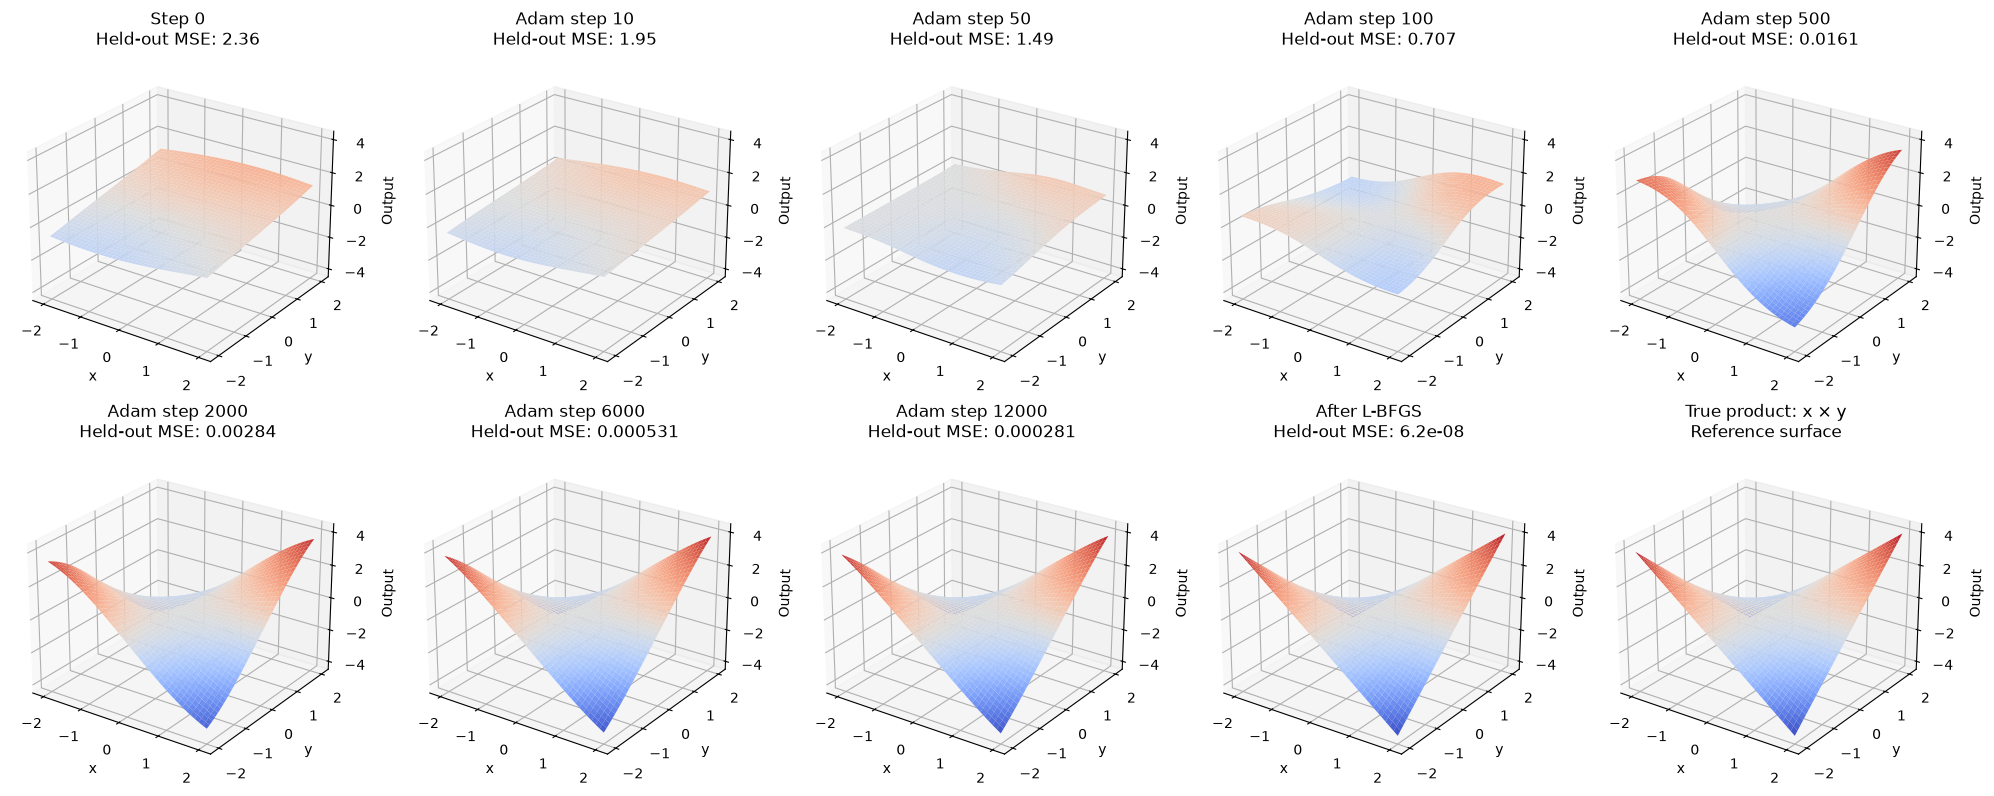

In [4]:
fig = plt.figure(figsize=(20, 8))
for i, (label, mse, surface) in enumerate(snapshots):
    ax = fig.add_subplot(2, 5, i + 1, projection="3d")
    ax.plot_surface(stage_xx.numpy(), stage_yy.numpy(), surface.numpy(),
                    cmap="coolwarm", vmin=-4, vmax=4, linewidth=0)
    ax.set(xlabel="x", ylabel="y", zlabel="Output", zlim=(-4.5, 4.5),
           title=f"{label}\nHeld-out MSE: {mse:.3g}")
    ax.view_init(elev=25, azim=-55)

ax = fig.add_subplot(2, 5, 10, projection="3d")
ax.plot_surface(stage_xx.numpy(), stage_yy.numpy(),
                (stage_xx * stage_yy).numpy(), cmap="coolwarm",
                vmin=-4, vmax=4, linewidth=0)
ax.set(xlabel="x", ylabel="y", zlabel="Output", zlim=(-4.5, 4.5),
       title="True product: x × y\nReference surface")
ax.view_init(elev=25, azim=-55)
plt.tight_layout()
plt.show()

## Inspect the four cases

1. Both inputs are in $[-1, 1]$.
2. Both inputs are in $[-2, -1] \cup [1, 2]$ (sample signs independently).
3. $x = 0$, with $y$ uniform on $[-2, 2]$.
4. $y = 0$, with $x$ uniform on $[-2, 2]$.

These cases are diagnostic slices, not a partition of the whole square: mixed inner/outer inputs are still included in training and the overall test set. The origin belongs to both zero-input slices.

Activation signs, saturation near ±1, and changes under input sign flips may suggest patterns. A neuron's activation alone does not establish what computation it performs.

In [5]:
def make_cases(n, seed):
    generator = torch.Generator().manual_seed(seed)
    inner = 2 * torch.rand(n, 2, generator=generator) - 1
    signs = 2 * torch.randint(0, 2, (n, 2), generator=generator) - 1
    outer = signs * (1 + torch.rand(n, 2, generator=generator))
    x_zero = 4 * torch.rand(n, 2, generator=generator) - 2
    x_zero[:, 0] = 0
    y_zero = 4 * torch.rand(n, 2, generator=generator) - 2
    y_zero[:, 1] = 0
    return {"Both inner": inner, "Both outer": outer,
            "x = 0": x_zero, "y = 0": y_zero}


def vector_string(values):
    return "[" + ", ".join(f"{v:+.3f}" for v in values.tolist()) + "]"


examples = make_cases(5, seed=123)
with torch.no_grad():
    for name, inputs in examples.items():
        hidden = model.activations(inputs)
        predictions = model(inputs)
        print(f"\n{name}")
        for i in range(len(inputs)):
            print(f"x={inputs[i, 0]:+.3f}  y={inputs[i, 1]:+.3f}  "
                  f"xy={product(inputs)[i, 0]:+.3f}  pred={predictions[i, 0]:+.3f}")
            print(f"  hidden={vector_string(hidden[i])}")


Both inner
x=-0.408  y=+0.033  xy=-0.014  pred=-0.013
  hidden=[-0.804, -0.835, -0.823, +0.835]
x=-0.497  y=+0.377  xy=-0.187  pred=-0.187
  hidden=[-0.790, -0.841, -0.816, +0.846]
x=-0.852  y=+0.733  xy=-0.625  pred=-0.624
  hidden=[-0.763, -0.840, -0.817, +0.864]
x=-0.727  y=-0.795  xy=+0.578  pred=+0.578
  hidden=[-0.817, -0.802, -0.855, +0.823]
x=-0.632  y=+0.453  xy=-0.286  pred=-0.286
  hidden=[-0.782, -0.839, -0.818, +0.852]

Both outer
x=+1.854  y=+1.593  xy=+2.953  pred=+2.953
  hidden=[-0.834, -0.914, -0.655, +0.805]
x=-1.637  y=+1.983  xy=-3.245  pred=-3.244
  hidden=[-0.674, -0.848, -0.807, +0.904]
x=-1.274  y=+1.658  xy=-2.114  pred=-2.114
  hidden=[-0.707, -0.850, -0.804, +0.892]
x=-1.278  y=+1.857  xy=-2.373  pred=-2.373
  hidden=[-0.699, -0.854, -0.798, +0.895]
x=+1.899  y=-1.039  xy=-1.973  pred=-1.974
  hidden=[-0.892, -0.871, -0.770, +0.708]

x = 0
x=+0.000  y=+0.955  xy=+0.000  pred=-0.000
  hidden=[-0.790, -0.867, -0.777, +0.846]
x=+0.000  y=+0.823  xy=+0.000  pre

## Inverse probes: one activation → two inputs

For each of the four hidden neurons, fit a separate **1 → 32 → 32 → 2** tanh decoder to the original inputs. The multiplication model is frozen: activations are detached and its weights never enter a probe optimizer.

Output order does not matter. For each example, use
$$L_i=\min\left(\frac{(\hat x_i-x_i)^2+(\hat y_i-y_i)^2}{2},\frac{(\hat x_i-y_i)^2+(\hat y_i-x_i)^2}{2}\right),\qquad L=\frac1N\sum_i L_i.$$
The minimum is taken **per example before averaging**, during both training and evaluation. A single scalar generally cannot reconstruct two independent inputs exactly; these probes measure what each neuron retains. Probe reconstruction MSE is distinct from the multiplication model's MSE and need not fall below 0.001.

Probes use fresh full batches of 4,096 examples, 3,000 Adam updates, and training-only standardization of each scalar activation. Validation curves use a separate fixed set. The final test set is evaluated only after fitting.

Neuron 1: training unordered MSE = 0.680164; validation unordered MSE = 0.675328


Neuron 2: training unordered MSE = 0.165858; validation unordered MSE = 0.166290


Neuron 3: training unordered MSE = 0.165900; validation unordered MSE = 0.166304


Neuron 4: training unordered MSE = 0.680259; validation unordered MSE = 0.675357


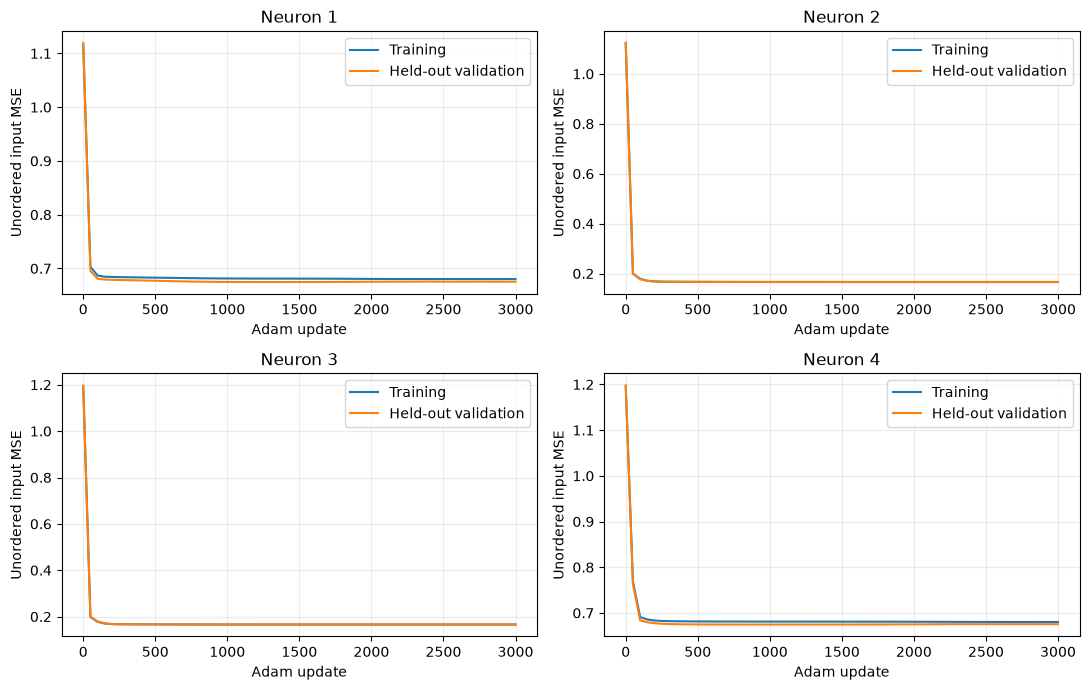

In [6]:
def unordered_mse(prediction, target):
    direct = (prediction - target).square().mean(dim=-1)
    swapped = (prediction - target.flip(-1)).square().mean(dim=-1)
    return torch.minimum(direct, swapped).mean()


class InverseProbe(nn.Module):
    def __init__(self, features):
        super().__init__()
        self.register_buffer("center", features.mean(dim=0))
        self.register_buffer("scale", features.std(dim=0).clamp_min(1e-6))
        self.decoder = nn.Sequential(
            nn.Linear(1, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 2),
        )

    def forward(self, z):
        return self.decoder((z - self.center) / self.scale)


torch.manual_seed(7)
probe_train_x = sample_inputs(4096)
probe_validation_x = sample_inputs(4096, generator=torch.Generator().manual_seed(8))
with torch.no_grad():
    probe_features = model.activations(probe_train_x)
    probe_validation_features = model.activations(probe_validation_x)

probe_steps = 3000
probes, probe_histories = [], []
for neuron in range(4):
    features = probe_features[:, neuron:neuron + 1]
    validation_features = probe_validation_features[:, neuron:neuron + 1]
    probe = InverseProbe(features)
    optimizer = torch.optim.Adam(probe.parameters(), lr=0.003)
    history = {"step": [], "train": [], "validation": []}
    for step in range(probe_steps + 1):
        if step % 50 == 0:
            with torch.no_grad():
                history["step"].append(step)
                history["train"].append(unordered_mse(probe(features), probe_train_x).item())
                history["validation"].append(
                    unordered_mse(probe(validation_features), probe_validation_x).item()
                )
        if step == probe_steps:
            break
        optimizer.zero_grad()
        loss = unordered_mse(probe(features), probe_train_x)
        loss.backward()
        optimizer.step()
    probe.eval()
    probes.append(probe)
    probe_histories.append(history)
    print(f"Neuron {neuron + 1}: training unordered MSE = {history['train'][-1]:.6f}; "
          f"validation unordered MSE = {history['validation'][-1]:.6f}")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for neuron, (ax, history) in enumerate(zip(axes.flat, probe_histories)):
    for split, label in [("train", "Training"), ("validation", "Held-out validation")]:
        ax.plot(history["step"], history[split], label=label)
    ax.set(title=f"Neuron {neuron + 1}", xlabel="Adam update", ylabel="Unordered input MSE")
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

## Inverse probes in 3D: $(z,\hat x,\hat y)$

Each point has one activation coordinate and two input coordinates. For every held-out example, compare the direct and swapped predicted pair against its **original ordered** input pair, then show **only the assignment with lower pair MSE**, exactly as in the unordered loss. Both predicted coordinates contribute to that loss; it does not select one output and discard the other. Ties keep the direct assignment.

Orange points show the winning predicted pairs; opaque dark-blue points show the actual $(z,x,y)$ examples. A few lines connect corresponding true and predicted points. Titles report unordered MSE on all 4,096 validation examples; the plot displays a fixed subset for readability.

The winning ordering uses the known target for evaluation. It cannot be chosen from $z$ alone, so these target-aligned samples are plotted as points rather than a continuous decoder curve. Swapping only reassigns output coordinates; it does not improve the unordered MSE.


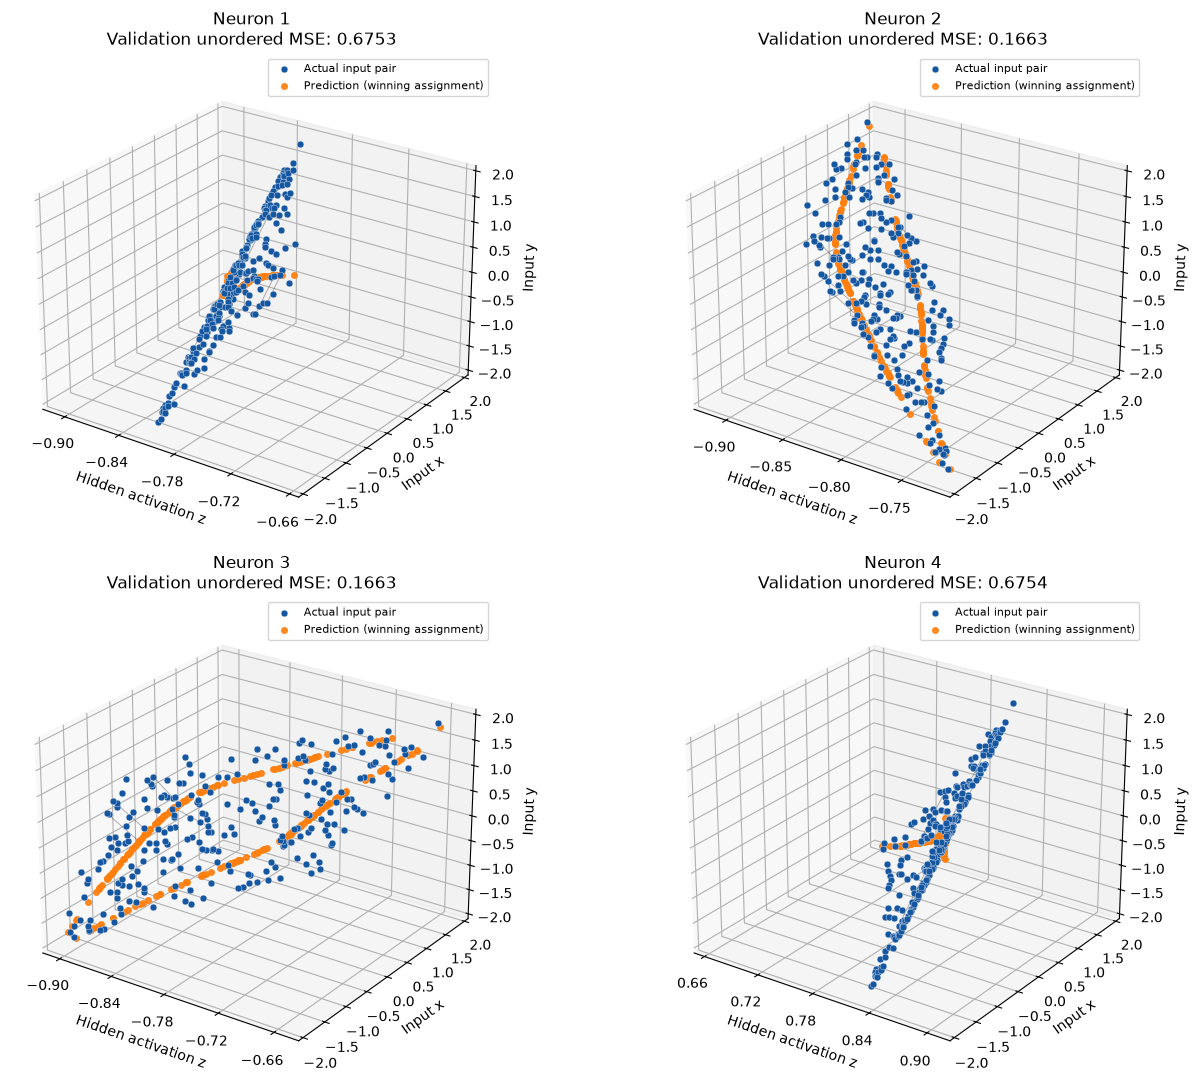

In [7]:
def best_input_pair(prediction, target):
    direct = (prediction - target).square().mean(dim=-1)
    swapped_prediction = prediction.flip(-1)
    swapped = (swapped_prediction - target).square().mean(dim=-1)
    return torch.where((swapped < direct).unsqueeze(-1), swapped_prediction, prediction)


from matplotlib.ticker import MaxNLocator

fig = plt.figure(figsize=(14, 11))
with torch.no_grad():
    truth = probe_validation_x
    for neuron, probe in enumerate(probes):
        z = probe_validation_features[:, neuron:neuron + 1]
        prediction = probe(z)
        matched = best_input_pair(prediction, truth)
        mse = unordered_mse(prediction, truth).item()
        # Coordinate matching must agree with the loss, including per-example swaps.
        torch.testing.assert_close((matched - truth).square().mean(),
                                   unordered_mse(prediction, truth))
        shown = torch.arange(0, len(z), 16)
        ax = fig.add_subplot(2, 2, neuron + 1, projection="3d")
        ax.scatter(z[shown, 0].numpy(), truth[shown, 0].numpy(), truth[shown, 1].numpy(),
                   color="#1556a0", s=24, alpha=1.0, depthshade=False,
                   edgecolors="white", linewidths=0.25, label="Actual input pair")
        ax.scatter(z[shown, 0].numpy(), matched[shown, 0].numpy(), matched[shown, 1].numpy(),
                   color="tab:orange", s=16, alpha=0.9, depthshade=False,
                   label="Prediction (winning assignment)")
        for row in shown[::32]:
            ax.plot([z[row, 0].item()] * 2,
                    [truth[row, 0].item(), matched[row, 0].item()],
                    [truth[row, 1].item(), matched[row, 1].item()],
                    color="black", alpha=0.3, linewidth=0.7)
        ax.set(title=f"Neuron {neuron + 1}\nValidation unordered MSE: {mse:.4f}",
               xlabel="Hidden activation z", ylabel="Input x", zlabel="Input y",
               ylim=(-2.1, 2.1), zlim=(-2.1, 2.1))
        ax.xaxis.set_major_locator(MaxNLocator(5))
        ax.view_init(elev=25, azim=-55)
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## Held-out errors and the four cases

The multiplication column measures scalar output MSE against $xy$. Each probe column measures the unordered two-input reconstruction MSE defined above. The whole-square row uses the independent final test set; the four diagnostic slices use fresh examples. Five-example tables print actual unordered reconstructed pairs, sorted for readability.

In [8]:
evaluation_cases = {"Whole square": test_x, **make_cases(1024, seed=456)}
print("Aggregate errors are MSE; probe columns use per-example unordered input MSE.")
print(f"{'Case':<16} {'NN vs xy':>12}" + "".join(f"{'Probe ' + str(i + 1):>12}" for i in range(4)))
with torch.no_grad():
    for name, inputs in evaluation_cases.items():
        hidden = model.activations(inputs)
        errors = [loss_fn(model(inputs), product(inputs)).item()]
        errors += [unordered_mse(probe(hidden[:, i:i + 1]), inputs).item()
                   for i, probe in enumerate(probes)]
        print(f"{name:<16}" + "".join(f"{error:12.6f}" for error in errors))

    print("\nFive-example unordered reconstructions (lower, upper):")
    for name, inputs in examples.items():
        hidden = model.activations(inputs)
        pairs = [probe(hidden[:, i:i + 1]).sort(dim=1).values for i, probe in enumerate(probes)]
        print(f"\n{name}")
        for row in range(len(inputs)):
            print(f"True {vector_string(inputs[row].sort().values)} | " + " | ".join(
                f"P{i + 1} {vector_string(pair[row])}" for i, pair in enumerate(pairs)))

Aggregate errors are MSE; probe columns use per-example unordered input MSE.
Case                 NN vs xy     Probe 1     Probe 2     Probe 3     Probe 4
Whole square        0.000000    0.655792    0.174974    0.175070    0.655611
Both inner          0.000000    0.178278    0.299869    0.299867    0.178093
Both outer          0.000000    1.139539    0.205970    0.206349    1.139804
x = 0               0.000000    0.466761    0.257900    0.258200    0.466540
y = 0               0.000000    0.234800    0.249317    0.249568    0.236002

Five-example unordered reconstructions (lower, upper):

Both inner
True [-0.408, +0.033] | P1 [-0.323, +0.138] | P2 [-1.112, +0.710] | P3 [-1.112, +0.709] | P4 [-0.328, +0.120]
True [-0.497, +0.377] | P1 [-0.550, +0.313] | P2 [-1.044, +0.857] | P3 [-1.037, +0.852] | P4 [-0.547, +0.326]
True [-0.852, +0.733] | P1 [-0.941, +0.630] | P2 [-1.062, +0.824] | P3 [-1.056, +0.820] | P4 [-0.938, +0.631]
True [-0.795, -0.727] | P1 [-0.054, -0.045] | P2 [-1.385, -0.1

## Final multiplication surface

Compare the target product with the trained 2 → 4 → 1 network on the same grid and axes.

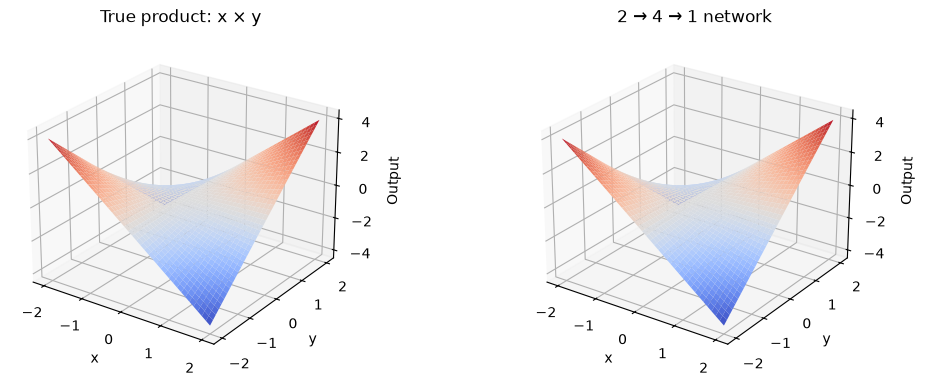

In [9]:
axis = torch.linspace(-2, 2, 81)
xx, yy = torch.meshgrid(axis, axis, indexing="xy")
grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)
with torch.no_grad():
    surfaces = [product(grid).reshape(xx.shape), model(grid).reshape(xx.shape)]
fig = plt.figure(figsize=(11, 4))
for i, (title, surface) in enumerate(zip(["True product: x × y", "2 → 4 → 1 network"], surfaces)):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.plot_surface(xx.numpy(), yy.numpy(), surface.numpy(), cmap="coolwarm",
                    vmin=-4, vmax=4, linewidth=0)
    ax.set(xlabel="x", ylabel="y", zlabel="Output", title=title, zlim=(-4.5, 4.5))
    ax.view_init(elev=25, azim=-55)
plt.tight_layout()
plt.show()